# Sismicidad de Chile: el catálogo USGS en el Lakehouse

**Consumo 5 · Consultas ad-hoc y exploración.** Este notebook lee directo del **Data Lakehouse**
(Apache Iceberg sobre MinIO) que carga Airflow, sin copiar los datos.

**Preguntas que responde:** ¿cómo evoluciona la sismicidad mes a mes y en cada macrozona?, ¿cuántos
sismos grandes cabe esperar en un año? y ¿con qué versión exacta del catálogo se calculó cada cifra?

| Herramienta | Para qué se usa |
| --- | --- |
| **PyIceberg** | Lee el catálogo REST de Iceberg y los Parquet de MinIO: particiones, versiones (*snapshots*) y *Time Travel* |
| **DuckDB** | SQL sobre lo que entrega PyIceberg (tablas Arrow), en memoria y sin copiar archivos |
| **matplotlib** | Gráficos para el informe |

Tablas: `gold.usgs_resumen_mensual` (indicadores por mes, calculados por Airflow) y
`silver.usgs_sismos` (un registro por sismo, particionada por mes de forma oculta).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import conexiones as cx

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

cat = cx.catalogo()
silver = cat.load_table(cx.SILVER_TABLA)
gold = cat.load_table(cx.GOLD_TABLA)
vigente = silver.current_snapshot()
print(f"{cx.SILVER_TABLA}: {vigente.summary['total-records']} sismos | snapshot vigente {vigente.snapshot_id} "
      f"| {len(silver.snapshots())} versiones")
print(f"Archivos de la tabla en MinIO: {silver.location()}")

silver.usgs_sismos: 653 sismos | snapshot vigente 7590353868546069162 | 13 versiones
Archivos de la tabla en MinIO: s3://lakehouse/warehouse/silver/usgs_sismos


## 1. Resumen mensual (capa gold)

Cada fila la calcula la tarea `cargar_lakehouse` de Airflow a partir de silver. La columna
`snapshot_silver` dice desde qué versión de silver salió (linaje).

In [2]:
resumen = gold.scan().to_pandas().sort_values("mes").set_index("mes")
resumen.drop(columns="calculado_utc")

,sismos,magnitud_max,magnitud_promedio,sismos_m4_o_mas,sismos_m5_o_mas,superficiales_menos_70km,profundidad_promedio_km,snapshot_silver
mes,,,,,,,,
2026-01-01,54,5.3,4.33,51,3,14,108.0,6202950610369543983
2026-02-01,62,6.1,4.39,61,2,15,121.0,1133374740670155651
2026-03-01,75,6.2,4.41,74,5,38,84.6,248800440342837940
2026-04-01,59,5.2,4.24,54,1,28,96.5,1302602817515652072
2026-05-01,96,6.9,4.41,95,4,34,103.6,8950433469911153490
2026-06-01,61,5.5,4.36,60,4,22,99.3,7299725660982883627
2026-07-01,70,5.3,4.41,67,7,34,89.6,2089652742168289851
2026-08-01,56,4.7,4.38,55,0,10,123.0,1718702836069441428
2026-09-01,62,5.3,4.41,57,6,28,87.6,5758370619860188114


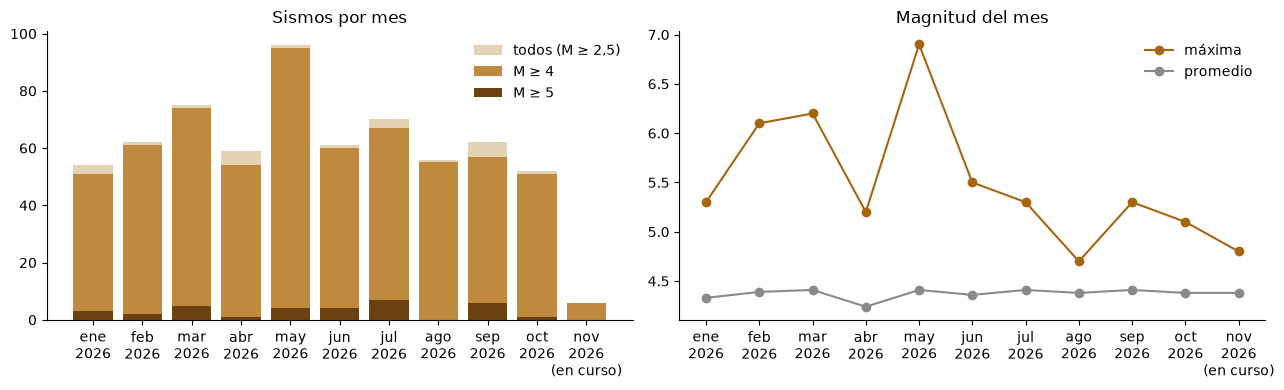

In [3]:
hoy = pd.Timestamp.now(tz="UTC")
# un mes que aún no termina se marca "en curso": sus barras no son comparables con las de los demás
etiquetas = [f"{MESES[m.month - 1]}\n{m.year}" + ("\n(en curso)" if (m + pd.offsets.MonthBegin()) > hoy else "")
             for m in pd.to_datetime(resumen.index).tz_localize("UTC")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(etiquetas, resumen["sismos"], color="#e3d3b4", label="todos (M ≥ 2,5)")
ax1.bar(etiquetas, resumen["sismos_m4_o_mas"], color="#c08a3e", label="M ≥ 4")
ax1.bar(etiquetas, resumen["sismos_m5_o_mas"], color="#6b4110", label="M ≥ 5")
ax1.set_title("Sismos por mes")
ax1.legend(frameon=False)
ax2.plot(etiquetas, resumen["magnitud_max"], marker="o", color="#a8650f", label="máxima")
ax2.plot(etiquetas, resumen["magnitud_promedio"], marker="o", color="#8a8a8a", label="promedio")
ax2.set_title("Magnitud del mes")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Consultas ad-hoc con DuckDB sobre silver

`scan().to_duckdb()` entrega la tabla Iceberg a DuckDB como Arrow, y DuckDB la consulta con SQL en
memoria. La macrozona se asigna por latitud. Ojo: el rectángulo del catálogo (latitud −17° a −56°,
longitud −76° a −66°) también incluye zonas fronterizas de Argentina y Bolivia.

In [4]:
con = silver.scan().to_duckdb(table_name="sismos")
macrozona = cx.sql_macrozona()

por_macrozona = con.sql(f"""
    SELECT {macrozona} AS macrozona,
           count(*)                                   AS sismos,
           count(*) FILTER (magnitud >= 4)            AS m4_o_mas,
           count(*) FILTER (magnitud >= 5)            AS m5_o_mas,
           max(magnitud)                              AS magnitud_max,
           round(avg(profundidad_km))                 AS profundidad_media_km,
           round(100 * avg((profundidad_km < 70)::INT)) AS pct_superficiales
    FROM sismos
    GROUP BY macrozona
    ORDER BY max(latitud) DESC
""").df()
por_macrozona

,macrozona,sismos,m4_o_mas,m5_o_mas,magnitud_max,profundidad_media_km,pct_superficiales
0,Norte Grande,396,383,13,6.9,133.0,15.0
1,Norte Chico,145,141,14,6.2,62.0,61.0
2,Centro,68,64,4,6.0,41.0,81.0
3,Sur,36,35,1,5.5,37.0,92.0
4,Austral,8,8,1,5.2,15.0,100.0


Sismos M ≥ 4 de cada macrozona, mes a mes:

In [5]:
con.sql(f"""
    PIVOT (SELECT {macrozona} AS macrozona, strftime(tiempo_utc, '%Y-%m') AS mes
           FROM sismos WHERE magnitud >= 4)
    ON mes USING count(*) GROUP BY macrozona ORDER BY macrozona
""").df().set_index("macrozona").reindex([m[0] for m in cx.MACROZONAS]).fillna(0).astype(int)

,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
macrozona,,,,,,,,,,,
Norte Grande,32,45,36,31,65,36,29,41,34,28,6
Norte Chico,11,11,21,11,20,17,17,8,12,13,0
Centro,3,2,9,7,5,7,15,5,5,6,0
Sur,3,1,8,2,5,0,6,1,5,4,0
Austral,2,2,0,3,0,0,0,0,1,0,0


Los diez sismos de mayor magnitud del período:

In [6]:
con.sql("""
    SELECT tiempo_utc, magnitud, tipo_magnitud, round(profundidad_km) AS profundidad_km, lugar, event_id
    FROM sismos ORDER BY magnitud DESC LIMIT 10
""").df()

,tiempo_utc,magnitud,tipo_magnitud,profundidad_km,lugar,event_id
0,2026-05-25 21:52:20.140+00:00,6.9,mww,109.0,"34 km ENE of Calama, Chile",us6000t04s
1,2026-03-13 13:39:21.201+00:00,6.2,mww,24.0,"71 km W of Vallenar, Chile",us6000sg0y
2,2026-02-12 13:34:31.172+00:00,6.1,mww,46.0,"28 km SW of Ovalle, Chile",us6000s8gw
3,2026-05-31 21:34:17.953+00:00,6.0,mww,25.0,"33 km NW of Valparaíso, Chile",us7000spqc
4,2026-02-08 16:23:57.357+00:00,5.7,mww,114.0,"79 km ENE of La Tirana, Chile",us6000s7ab
5,2026-03-21 10:00:38.214+00:00,5.6,mww,196.0,"82 km WNW of San Antonio de los Cobres, Argentina",us6000si4j
6,2026-06-11 12:22:06.893+00:00,5.5,mww,9.0,"124 km NW of Vallenar, Chile",us7000ss82
7,2026-05-10 02:34:07.091+00:00,5.5,mww,35.0,"19 km ENE of Cañete, Chile",us6000swk0
8,2026-09-20 08:47:54.359+00:00,5.3,mww,10.0,"61 km WNW of Cafayate, Argentina",us7000tiq2
9,2026-07-24 19:38:41.905+00:00,5.3,mww,190.0,"43 km NW of San Antonio de los Cobres, Argentina",us7000t36n


## 3. Dónde y a qué profundidad

A la izquierda, los epicentros (tamaño según magnitud, color según profundidad). A la derecha, la
profundidad según la longitud: los sismos se hunden hacia el este siguiendo la placa de Nazca, que
se mete bajo la Sudamericana (zona de Wadati-Benioff). Los superficiales del oeste son los de la
interfaz entre las placas, los que generan los grandes terremotos y tsunamis.

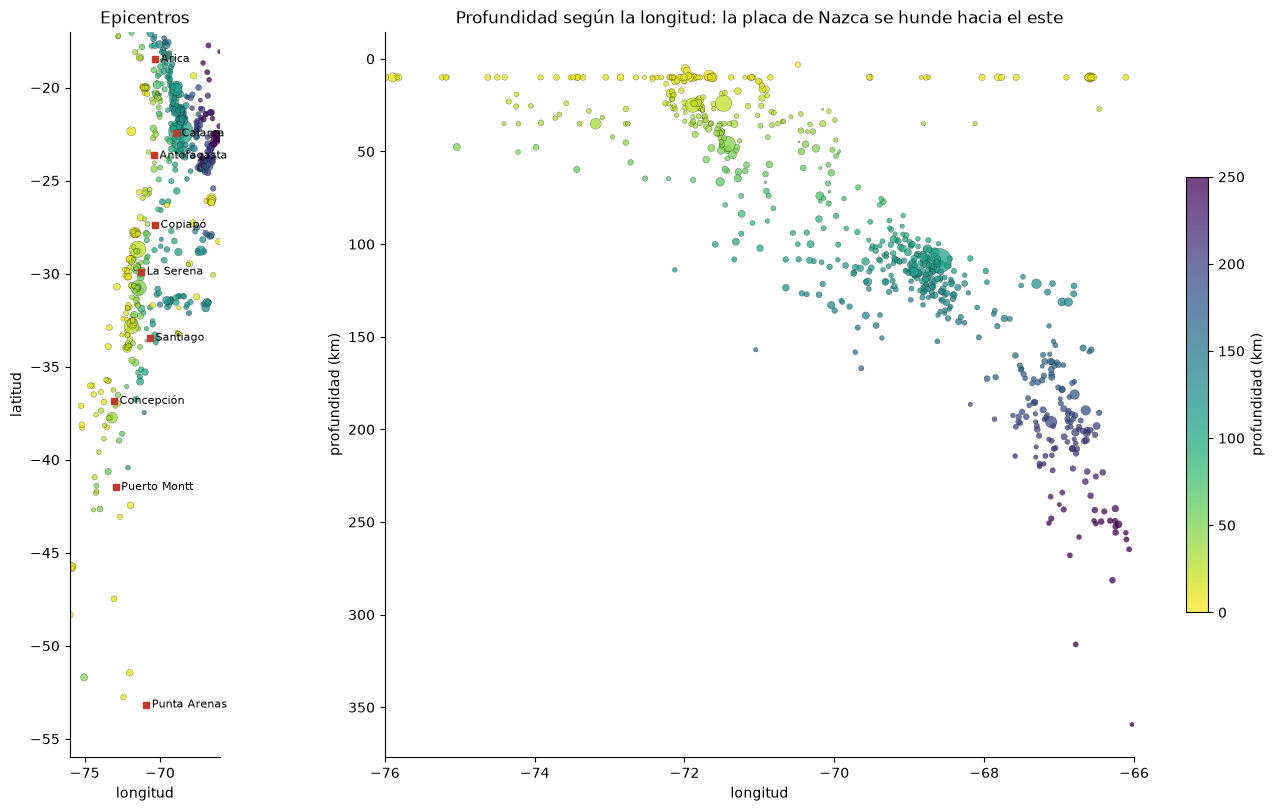

In [7]:
sismos = con.sql("SELECT latitud, longitud, profundidad_km, magnitud FROM sismos").df()
fig, (mapa, perfil) = plt.subplots(1, 2, figsize=(13, 8), layout="constrained",
                                   gridspec_kw={"width_ratios": [1, 2.2]})
puntos = mapa.scatter(sismos.longitud, sismos.latitud, s=1.8 ** (2 * sismos.magnitud - 4),
                      c=sismos.profundidad_km, cmap="viridis_r", vmin=0, vmax=250, alpha=0.75,
                      edgecolor="k", linewidth=0.2)
for ciudad, (lat, lon) in cx.CIUDADES.items():
    mapa.plot(lon, lat, "s", color="#c0392b", ms=4)
    mapa.annotate(ciudad, (lon, lat), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
mapa.set(xlim=(-76, -66), ylim=(-56, -17), xlabel="longitud", ylabel="latitud", title="Epicentros")
mapa.set_aspect(1 / np.cos(np.radians(-36)))
perfil.scatter(sismos.longitud, sismos.profundidad_km, s=1.8 ** (2 * sismos.magnitud - 4),
               c=sismos.profundidad_km, cmap="viridis_r", vmin=0, vmax=250, alpha=0.75,
               edgecolor="k", linewidth=0.2)
perfil.invert_yaxis()
perfil.set(xlim=(-76, -66), xlabel="longitud", ylabel="profundidad (km)",
           title="Profundidad según la longitud: la placa de Nazca se hunde hacia el este")
fig.colorbar(puntos, ax=perfil, label="profundidad (km)", shrink=0.6)
for ax in (mapa, perfil):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. ¿Cuántos sismos grandes cabe esperar? Ley de Gutenberg-Richter

En una región, la cantidad de sismos de magnitud mayor o igual a M sigue `log10 N(≥M) = a − b·M`:
por cada sismo M6 hay unos 10 M5 si b ≈ 1. Con el catálogo se estima:

1. La **magnitud de completitud** Mc, desde la que el catálogo registra todos los sismos (método de
   máxima curvatura, + 0,2).
2. El **valor b** por máxima verosimilitud (Aki-Utsu): `b = log10(e) / (M̄ − (Mc − ΔM/2))`.
3. Con a y b, la cantidad esperada por año de sismos sobre cada magnitud.

Son pocos meses de datos, así que es una estimación exploratoria: sirve para informar órdenes de
magnitud, no para un estudio de peligro sísmico. Además, bajo M5,5 casi todo el catálogo viene en
magnitud de ondas de cuerpo (`mb`), que se satura y comprime las magnitudes: eso sube el valor b
(en zonas de subducción suele estar cerca de 1) y hace que la recta **subestime los sismos M6+**.
Por eso la tabla pone lado a lado lo observado y lo esperado.

In [8]:
m = sismos["magnitud"].round(1)
escalones = np.round(np.arange(m.min(), m.max() + 0.05, 0.1), 1)
por_escalon = m.value_counts().reindex(escalones, fill_value=0)
mc = round(float(por_escalon.idxmax()) + 0.2, 1)
completos = m[m >= mc - 1e-9]
b = np.log10(np.e) / (completos.mean() - (mc - 0.05))
error_b = b / np.sqrt(len(completos))
a = np.log10(len(completos)) + b * mc

periodo = con.sql("SELECT min(tiempo_utc) AS desde, max(tiempo_utc) AS hasta FROM sismos").df().iloc[0]
anios = (periodo.hasta - periodo.desde).total_seconds() / (365.25 * 86400)
print(f"Período: {periodo.desde:%Y-%m-%d} a {periodo.hasta:%Y-%m-%d} ({anios:.2f} años)")
print(f"Mc = {mc}  |  b = {b:.2f} ± {error_b:.2f}  |  {len(completos)} sismos sobre Mc")
print("Tipos de magnitud:", con.sql("SELECT tipo_magnitud, count(*) AS n FROM sismos GROUP BY 1 ORDER BY 2 DESC")
      .df().set_index("tipo_magnitud")["n"].to_dict())


def cada(anios_entre_sismos: float) -> str:
    if anios_entre_sismos < 1 / 12:
        return f"{anios_entre_sismos * 365.25:.0f} días"
    if anios_entre_sismos < 1:
        return f"{anios_entre_sismos * 12:.0f} meses"
    return f"{anios_entre_sismos:.0f} años"


pd.DataFrame([{"magnitud": f"M ≥ {M}",
               "observados en el período": int((m >= M).sum()),
               "observados por año": round(int((m >= M).sum()) / anios, 1),
               "esperados por año (G-R)": round(10 ** (a - b * M) / anios, 2),
               "un sismo cada (G-R)": cada(anios / 10 ** (a - b * M))} for M in (5, 6, 7, 8)])

Período: 2026-01-01 a 2026-11-03 (0.84 años)
Mc = 4.5  |  b = 1.50 ± 0.10  |  213 sismos sobre Mc
Tipos de magnitud: {'mb': 492, 'mwr': 113, 'mww': 39, 'ml': 9}


,magnitud,observados en el período,observados por año,esperados por año (G-R),un sismo cada (G-R)
0,M ≥ 5,33,39.3,45.00,8 días
1,M ≥ 6,4,4.8,1.41,8 meses
2,M ≥ 7,0,0.0,0.04,23 años
3,M ≥ 8,0,0.0,0.00,717 años


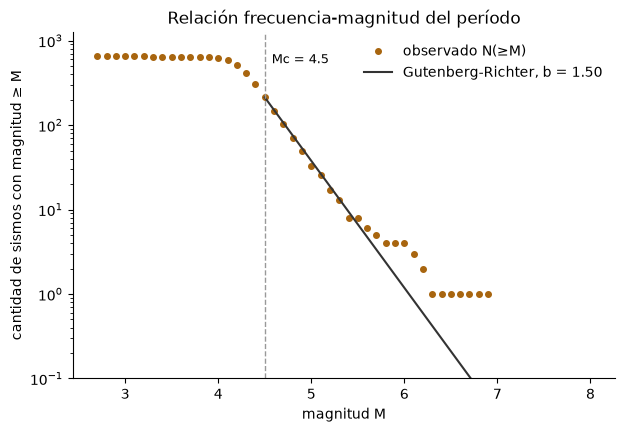

In [9]:
acumulado = pd.Series({M: int((m >= M - 1e-9).sum()) for M in escalones})
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(acumulado.index, acumulado.values, "o", color="#a8650f", ms=4, label="observado N(≥M)")
recta = np.linspace(mc, 8, 50)
ax.semilogy(recta, 10 ** (a - b * recta), color="#333", label=f"Gutenberg-Richter, b = {b:.2f}")
ax.axvline(mc, color="#999", ls="--", lw=1)
ax.annotate(f"Mc = {mc}", (mc, acumulado.max()), xytext=(5, -5), textcoords="offset points", fontsize=9)
ax.set(xlabel="magnitud M", ylabel="cantidad de sismos con magnitud ≥ M", ylim=(0.1, None),
       title="Relación frecuencia-magnitud del período")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Particiones ocultas: Iceberg solo lee los archivos que pueden servir

`silver.usgs_sismos` está particionada por el mes de `tiempo_utc` sin una columna extra
(*hidden partitioning*), y cada archivo guarda el mínimo y el máximo de cada columna. Antes de leer,
PyIceberg descarta los archivos que no pueden cumplir el filtro.

In [10]:
from pyiceberg.expressions import AlwaysTrue

filtros = {"sin filtro": AlwaysTrue(),
           "solo septiembre": "tiempo_utc >= '2026-09-01T00:00:00+00:00' AND tiempo_utc < '2026-10-01T00:00:00+00:00'",
           "magnitud ≥ 6": "magnitud >= 6.0"}
pd.DataFrame([{"consulta": nombre,
               "archivos Parquet a leer": len(list(silver.scan(row_filter=filtro).plan_files())),
               "filas que cumplen": len(silver.scan(row_filter=filtro, selected_fields=("event_id",)).to_arrow())}
              for nombre, filtro in filtros.items()])

,consulta,archivos Parquet a leer,filas que cumplen
0,sin filtro,11,653
1,solo septiembre,1,62
2,magnitud ≥ 6,3,4


## 6. Time Travel: el catálogo tal como estaba antes

Cada carga de Airflow es una versión (snapshot) de la tabla. Si un mes se vuelve a cargar (por
ejemplo, porque cuando se cargó por primera vez aún no terminaba) aparece un `delete` y un `append`
del mismo mes. Cualquier versión anterior se puede volver a leer tal cual estaba.

In [11]:
historial = cx.snapshots(silver)
historial

,committed_at,snapshot_id,operation,mes,origen,added-records,deleted-records,total-records
0,2026-11-04 18:12:18.513,6202950610369543983,append,2026-01,manual,54,<NA>,54
1,2026-11-04 18:12:21.941,1133374740670155651,append,2026-02,manual,62,<NA>,116
2,2026-11-04 18:12:24.407,248800440342837940,append,2026-03,manual,75,<NA>,191
3,2026-11-04 18:12:27.780,1302602817515652072,append,2026-04,manual,59,<NA>,250
4,2026-11-04 18:12:30.772,8950433469911153490,append,2026-05,manual,96,<NA>,346
5,2026-11-04 18:12:32.194,7299725660982883627,append,2026-06,manual,61,<NA>,407
6,2026-11-04 18:12:33.543,2089652742168289851,append,2026-07,manual,70,<NA>,477
7,2026-11-04 18:12:34.885,1718702836069441428,append,2026-08,manual,56,<NA>,533
8,2026-11-04 18:12:36.320,5758370619860188114,append,2026-09,manual,62,<NA>,595
9,2026-11-04 18:12:37.717,2887741029336855874,append,2026-10,manual,28,<NA>,623


Se compara la versión **justo antes de la última recarga** con la vigente (si ningún mes se ha
recargado, la primera versión). Para comparar con otra, cambien `ANTES` por un `snapshot_id` del
historial.

In [12]:
ANTES = None

borrados = historial["deleted-records"].fillna(0)
if ANTES is None:
    ANTES = int(historial.loc[borrados[borrados > 0].index[-1] - 1 if (borrados > 0).any() else 0, "snapshot_id"])
version = historial.set_index("snapshot_id").loc[ANTES]
print(f"Versión elegida: {ANTES} ({version.committed_at:%Y-%m-%d %H:%M:%S} UTC, carga de {version.mes}, "
      f"origen: {version.origen})")

silver.scan(snapshot_id=ANTES).to_duckdb(table_name="sismos_antes", connection=con)
con.sql("""
    SELECT coalesce(a.mes, b.mes) AS mes, coalesce(a.n, 0) AS en_esa_version, coalesce(b.n, 0) AS vigente,
           coalesce(b.n, 0) - coalesce(a.n, 0) AS diferencia
    FROM (SELECT strftime(tiempo_utc, '%Y-%m') AS mes, count(*) AS n FROM sismos_antes GROUP BY 1) a
    FULL JOIN (SELECT strftime(tiempo_utc, '%Y-%m') AS mes, count(*) AS n FROM sismos GROUP BY 1) b USING (mes)
    ORDER BY mes
""").df()

Versión elegida: 2887741029336855874 (2026-11-04 18:12:37 UTC, carga de 2026-10, origen: manual)


,mes,en_esa_version,vigente,diferencia
0,2026-01,54,54,0
1,2026-02,62,62,0
2,2026-03,75,75,0
3,2026-04,59,59,0
4,2026-05,96,96,0
5,2026-06,61,61,0
6,2026-07,70,70,0
7,2026-08,56,56,0
8,2026-09,62,62,0
9,2026-10,28,52,24


Sismos que están en la versión vigente y no en la anterior (o al revés). Con `event_id` se ve
exactamente qué cambió entre dos cortes del catálogo (aquí, los diez de mayor magnitud):

In [13]:
cambios = con.sql("""
    SELECT 'agregado' AS cambio, tiempo_utc, magnitud, round(profundidad_km) AS profundidad_km, lugar, event_id
    FROM sismos ANTI JOIN sismos_antes USING (event_id)
    UNION ALL
    SELECT 'quitado', tiempo_utc, magnitud, round(profundidad_km), lugar, event_id
    FROM sismos_antes ANTI JOIN sismos USING (event_id)
    ORDER BY magnitud DESC
""").df()
print(cambios.cambio.value_counts().to_dict())
cambios.head(10)

{'agregado': 30}


,cambio,tiempo_utc,magnitud,profundidad_km,lugar,event_id
0,agregado,2026-10-26 19:36:16.160+00:00,4.9,120.0,"100 km E of La Tirana, Chile",us7000ttbh
1,agregado,2026-11-01 05:31:54.598+00:00,4.8,202.0,"71 km NNW of San Antonio de los Cobres, Argentina",us7000tumy
2,agregado,2026-10-26 20:20:25.411+00:00,4.7,61.0,"7 km SE of Coquimbo, Chile",us7000ttbz
3,agregado,2026-10-22 21:37:56.543+00:00,4.6,142.0,"49 km S of Ollagüe, Chile",us6000u47n
4,agregado,2026-10-26 20:52:11.505+00:00,4.6,48.0,"20 km NNW of La Ligua, Chile",us7000ttc8
5,agregado,2026-10-27 11:41:22.141+00:00,4.6,206.0,"100 km W of El Aguilar, Argentina",us7000ttfs
6,agregado,2026-10-23 00:09:35.519+00:00,4.5,186.0,"102 km W of San Antonio de los Cobres, Argentina",us6000u48i
7,agregado,2026-10-23 02:45:41.183+00:00,4.5,236.0,"58 km SW of Atocha, Bolivia",us6000u49c
8,agregado,2026-10-27 11:19:39.073+00:00,4.5,113.0,"51 km S of Calingasta, Argentina",us7000ttfm
9,agregado,2026-11-01 23:18:05.811+00:00,4.5,244.0,"86 km WNW of Abra Pampa, Argentina",us7000tus5


## 7. Resumen para el informe

Las cifras quedan ligadas al snapshot con que se calcularon: con ese id, cualquiera puede volver a
leer exactamente los mismos datos (`silver.scan(snapshot_id=...)`), aunque el catálogo haya cambiado
después. La tabla por macrozona se exporta a `datos/informes/` con el id en el nombre.

In [14]:
mayor = con.sql("SELECT * FROM sismos ORDER BY magnitud DESC LIMIT 1").df().iloc[0]
mas_activa = por_macrozona.sort_values("m4_o_mas", ascending=False).iloc[0]
print(f"""INFORME DE SISMICIDAD · catálogo USGS, rectángulo de Chile continental
Período:          {periodo.desde:%d-%m-%Y} a {periodo.hasta:%d-%m-%Y}
Sismos:           {len(sismos)} (M ≥ 4: {(m >= 4).sum()}, M ≥ 5: {(m >= 5).sum()}, M ≥ 6: {(m >= 6).sum()})
Mayor sismo:      M{mayor.magnitud} el {mayor.tiempo_utc:%d-%m-%Y %H:%M} UTC, {mayor.lugar}, a {mayor.profundidad_km:.0f} km de profundidad
Más activa:       {mas_activa.macrozona} ({mas_activa.m4_o_mas} sismos M ≥ 4)
Gutenberg-Richter: b = {b:.2f} ± {error_b:.2f}; se esperan {10 ** (a - b * 6) / anios:.1f} sismos M ≥ 6 por año
Fuente:           {cx.SILVER_TABLA}, snapshot {vigente.snapshot_id}""")

cx.INFORMES.mkdir(parents=True, exist_ok=True)
archivo = cx.INFORMES / f"sismicidad_macrozonas_snapshot_{vigente.snapshot_id}.csv"
por_macrozona.to_csv(archivo, index=False)
print(f"\nTabla por macrozona exportada a datos/informes/{archivo.name}")

INFORME DE SISMICIDAD · catálogo USGS, rectángulo de Chile continental
Período:          01-01-2026 a 03-11-2026
Sismos:           653 (M ≥ 4: 631, M ≥ 5: 33, M ≥ 6: 4)
Mayor sismo:      M6.9 el 25-05-2026 21:52 UTC, 34 km ENE of Calama, Chile, a 109 km de profundidad
Más activa:       Norte Grande (383 sismos M ≥ 4)
Gutenberg-Richter: b = 1.50 ± 0.10; se esperan 1.4 sismos M ≥ 6 por año
Fuente:           silver.usgs_sismos, snapshot 7590353868546069162

Tabla por macrozona exportada a datos/informes/sismicidad_macrozonas_snapshot_7590353868546069162.csv
